# Stage 1 analysis
Reads only from `runs/` (copy them from the VM with rsync). Every figure comes from run folders, using the definitions in `load.py`.

In [1]:
import sys; sys.path.insert(0, '..')
import matplotlib.pyplot as plt
import pandas as pd
from analysis import load as L
FIG = __import__('pathlib').Path('figures'); FIG.mkdir(exist_ok=True)

## Run inventory and validity

In [2]:
runs = L.find_runs(valid_only=False)
pd.DataFrame([{'run': r['dir'].name, 'valid': r['checks'] and r['checks']['valid'],
               'failed': r['checks'] and r['checks']['failed']} for r in runs])

,run,valid,failed
0,20261023-145613_smoke,False,[gpu_steady]
1,20261023-145933_smoke,True,[]
2,20261030-114021_first_real,None,None
3,20261030-114115_first_real,True,[]
4,20261030-120420_repeat,True,[]
5,20261030-122024_repeat,True,[]
6,20261030-131243_sweep_pc_on_r1,True,[]
7,20261030-132844_sweep_pc_on_r2,True,[]
8,20261030-134449_sweep_pc_on_r3,True,[]
9,20261030-140051_sweep_pc_on_r4,True,[]


## One run over time
Set `RUN`. `SLO_TTFT` is fixed in `docs/decisions.md`.

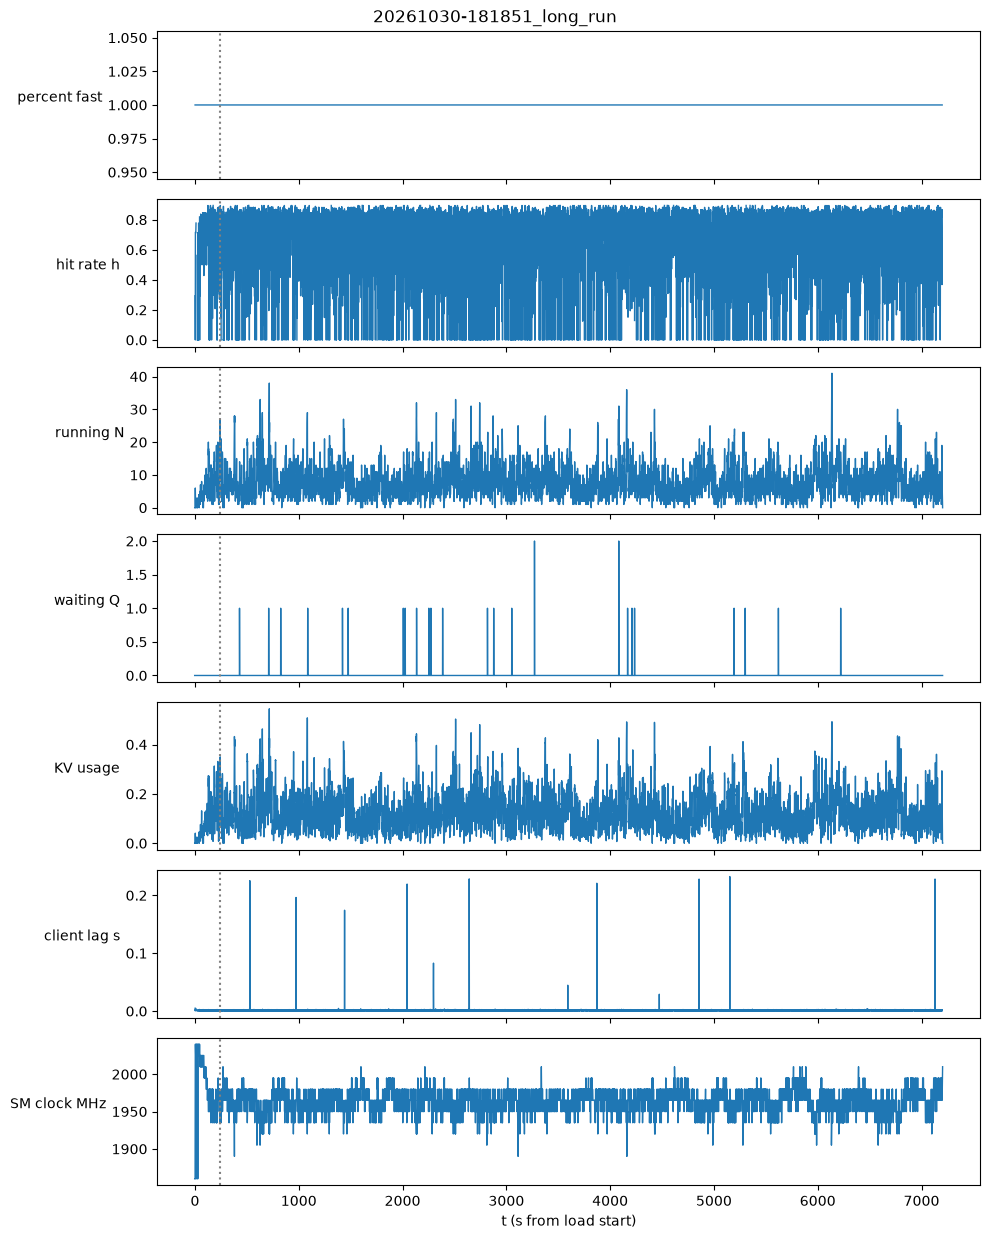

In [3]:
RUN = '20261030-181851_long_run'
SLO_TTFT = 1.0  # fixed in docs/decisions.md
run = L.load_run(L.RUNS / RUN)
m, g, req = L.rates(run['metrics']), run['gpu'], run['requests']
pf = L.percent_fast(req, SLO_TTFT)
panels = [('percent fast', pf.t, pf.percent_fast), ('hit rate h', m.t, m.get('hit_rate')),
          ('running N', m.t, m.get('num_requests_running')), ('waiting Q', m.t, m.get('num_requests_waiting')),
          ('KV usage', m.t, m.get('kv_cache_usage_perc')),
          ('client lag s', req.t_planned, req.t_sent - req.t_planned),
          ('SM clock MHz', g.get('t'), g.get('sm_clock_mhz'))]
panels = [p for p in panels if p[2] is not None]
fig, axs = plt.subplots(len(panels), 1, figsize=(10, 1.8 * len(panels)), sharex=True)
for ax, (name, x, y) in zip(axs, panels):
    ax.plot(x, y, lw=1); ax.set_ylabel(name, rotation=0, ha='right')
    ax.axvline(run['cfg']['workload']['warmup_s'], color='grey', ls=':')
axs[-1].set_xlabel('t (s from load start)'); fig.suptitle(RUN); fig.tight_layout()
fig.savefig(FIG / f'{RUN}_timeseries.png', dpi=120)

## Repeatability (run 3)
Compare `first_real` and `repeat` within the pre-registered tolerance in `docs/decisions.md`.

In [4]:
pd.DataFrame([L.summarize(r) for r in runs if r['checks'] and r['checks']['valid'] and r['cfg']['name'] in ('first_real', 'repeat')])

,run,rate,prefix_caching,throughput,ttft_p50,ttft_p99,e2e_p50,unfinished,hit_rate,q_mean,q_slope_per_s,valid
0,20261030-114115_first_real,2.0,True,1.986364,0.084083,0.288270,1.970003,0,0.732368,0.0,0.0,True
1,20261030-120420_repeat,2.0,True,1.986364,0.084667,0.293445,1.969855,0,0.732205,0.0,0.0,True
2,20261030-122024_repeat,2.0,True,1.986364,0.083968,0.286819,1.969088,0,0.732776,0.0,0.0,True


## Load–latency curves: prefix caching on vs off (runs 4–5)

,run,rate,prefix_caching,throughput,ttft_p50,ttft_p99,e2e_p50,unfinished,hit_rate,q_mean,q_slope_per_s,valid
7,20261030-154544_sweep_pc_off_r1,1,False,0.987879,0.227559,0.584800,2.146954,0,NaN,0.000000,0.000000,True
8,20261030-160147_sweep_pc_off_r2,2,False,1.981818,0.274437,0.941177,3.212083,0,NaN,0.012121,-0.000018,True
9,20261030-161749_sweep_pc_off_r3,3,False,2.906061,0.435220,7.373309,6.702233,0,NaN,1.687879,0.012976,True
10,20261030-163358_sweep_pc_off_r4,4,False,3.453030,40.993165,105.399331,56.681227,0,NaN,134.598485,0.637159,True
11,20261030-165151_sweep_pc_off_r5,5,False,3.510606,151.805864,317.966843,161.700935,188,NaN,561.134848,1.703815,True
12,20261030-171254_sweep_pc_off_r6,6,False,3.521212,236.120870,435.675561,249.427076,941,NaN,1026.693939,2.666281,True
13,20261030-173356_sweep_pc_off_r8,8,False,3.533333,347.398631,583.693797,356.369189,2536,NaN,1891.501515,4.772574,True
0,20261030-131243_sweep_pc_on_r1,1,True,0.990909,0.077486,0.146565,1.723311,0,0.729578,0.000000,0.000000,True
1,20261030-132844_sweep_pc_on_r2,2,True,1.983333,0.084047,0.294391,1.968189,0,0.732247,0.000000,0.000000,True
2,20261030-134449_sweep_pc_on_r3,3,True,3.000000,0.113699,0.463528,2.542410,0,0.627496,0.000000,0.000000,True


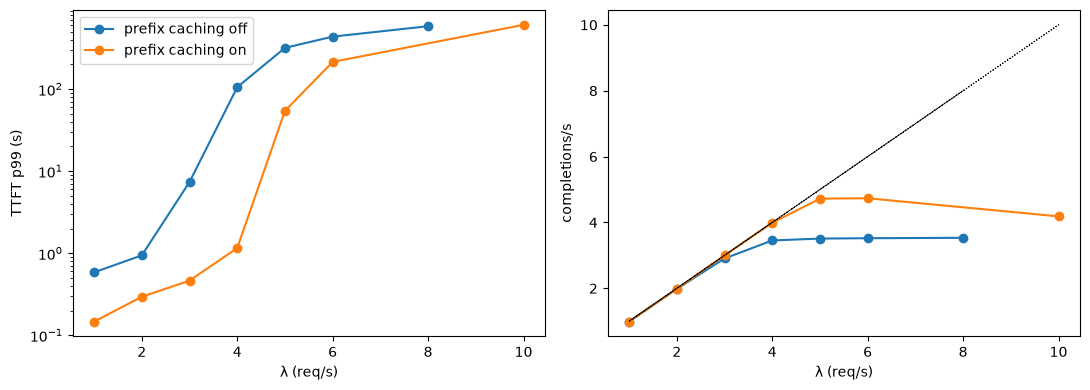

In [5]:
curve = pd.DataFrame([L.summarize(r) for r in runs if r['checks'] and r['checks']['valid'] and r['cfg'].get('sweep_parent') in ('sweep_pc_on', 'sweep_pc_off')])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
for pc, c in curve.groupby('prefix_caching'):
    c = c.sort_values('rate'); lab = 'prefix caching ' + ('on' if pc else 'off')
    a1.plot(c.rate, c.ttft_p99, 'o-', label=lab); a2.plot(c.rate, c.throughput, 'o-', label=lab)
a1.set(xlabel='λ (req/s)', ylabel='TTFT p99 (s)', yscale='log'); a2.plot(curve.rate, curve.rate, 'k:', lw=.8)
a2.set(xlabel='λ (req/s)', ylabel='completions/s'); a1.legend(); fig.tight_layout()
fig.savefig(FIG / 'load_latency.png', dpi=120); curve.sort_values(['prefix_caching', 'rate'])

### μ_warm and μ_off
Capacity thresholds must be written in `docs/decisions.md` **before** this cell is run.

In [ ]:
MIN_TPUT_FRAC, MAX_Q_SLOPE = 0.95, 0.01  # copy from decisions.md
{('mu_warm' if pc else 'mu_off'): L.capacity(c, MIN_TPUT_FRAC, MAX_Q_SLOPE) for pc, c in curve.groupby('prefix_caching')}

## Does the recorder slow the server? (open question 5)
Recorder-off runs against the same rates of `sweep_pc_on`. Limits are in `docs/decisions.md`.

In [ ]:
def row(r):
    s = L.summarize(r)
    return {'rate': s['rate'], 'throughput': s['throughput'], 'ttft_p50': s['ttft_p50'], 'ttft_p99': s['ttft_p99'],
            'hit_rate': L.whole_run_hit_rate(r), 'backlog_slope': L.client_backlog_slope(r), 'valid': s['valid']}
pick = lambda parent: pd.DataFrame([row(r) for r in runs if r['cfg'].get('sweep_parent') == parent and r['cfg']['workload']['rate'] in (3, 4, 5)]).set_index('rate')
on, off = pick('sweep_pc_on'), pick('recorder_off')
pd.DataFrame({'throughput_pct': 100 * (off.throughput / on.throughput - 1), 'ttft_p50_pct': 100 * (off.ttft_p50 / on.ttft_p50 - 1),
              'ttft_p99_pct': 100 * (off.ttft_p99 / on.ttft_p99 - 1), 'hit_rate_diff': off.hit_rate - on.hit_rate,
              'off_keeps_up': (off.throughput >= 0.95 * off.index) & (off.backlog_slope <= 0.01), 'on_keeps_up': (on.throughput >= 0.95 * on.index) & (on.backlog_slope <= 0.01)})